# Evaluasi *Test Set* Mandiri dan *Inference* Model *Instance Segmentation*

**Ringkasan.** Notebook ini menguji sembilan *checkpoint* terlatih dari tiga keluarga arsitektur (`YOLO26s-seg`, `Mask R-CNN R50-FPN v2`, dan `RF-DETR-Seg Small` pada target ukuran `320`, `640`, dan `960` piksel) terhadap **Dataset Roboflow `panoptic-indoor-segmentation-zsgy2` versi 2 (`dataset final fazle`)** yang memuat *split* `test` ruangan nyata hasil pemotretan pribadi. Seluruh evaluasi dijalankan dengan Google Drive untuk memuat bobot pelatihan serta menyimpan hasil secara persisten.

## Tujuan dan Hipotesis Uji

**Tujuan**
1. Memuat kesembilan *checkpoint* terbaik (`best.pt` dan `checkpoint_best_total.pth`) bersama `handoff_manifest.json` dari Google Drive atau folder lokal secara otomatis.
2. Mengevaluasi performa tiap model pada *split* `test` dan membandingkannya dengan `valid` menggunakan evaluator COCO (`pycocotools`, `segm`) yang sama persis.
3. Mengukur besar *domain shift* (`test - valid`) serta *trade-off* antara akurasi dan waktu *inference* per gambar.
4. Memvisualisasikan perbandingan prediksi tiga model terhadap *ground truth*, analisis 5 kegagalan terburuk, serta rincian AP per kelas pada `test`.

**Hipotesis yang Diuji**
- **H3.** Karena foto *test* berasal dari kamera HP beresolusi tinggi (`3000x4000 px`), menaikkan ukuran input dari `640` ke `960` piksel diprediksi menghasilkan kenaikan *mask* mAP yang lebih besar dibandingkan selisihnya pada *split* `valid`.
- **Domain Shift.** Perubahan pencahayaan ruangan nyata (*low-light* dan *backlight*), sudut pengambilan, serta kepadatan objek pada `test` diprediksi menurunkan skor relatif terhadap `valid`.

## 1. Konfigurasi dan *Mount* Google Drive

Ketika `USE_GOOGLE_DRIVE = True`, sel di bawah me-mount Google Drive ke `/content/drive` dan mencari lokasi bobot pelatihan secara otomatis pada beberapa path kandidat (`MyDrive/colab_outputs`, `MyDrive/instance_seg_colab_outputs`, `MyDrive/instance_seg_colab_runs`, atau file `.zip` hasil unduhan). Seluruh hasil evaluasi berupa CSV, grafik, dan visualisasi disimpan ke `OUT` di Google Drive.

In [1]:
from pathlib import Path
import hashlib, json, os, shutil, subprocess, sys, time, zipfile

# --- Roboflow Dataset Versi Final (Memuat Split test) ---
ROBOFLOW_WORKSPACE = "fasel"
ROBOFLOW_PROJECT = "panoptic-indoor-segmentation-zsgy2"
ROBOFLOW_VERSION = 2  # dataset final fazle

# --- Pengaturan Google Drive & Lokasi Bobot ---
USE_GOOGLE_DRIVE = True
# Opsional: isi path spesifik di Drive jika folder/zip ditaruh di subdirektori khusus, misal "/content/drive/MyDrive/Comvis/colab_outputs"
CUSTOM_DRIVE_WEIGHTS_PATH = ""

DRIVE_EVAL_DIR = Path("/content/drive/MyDrive/instance_seg_inference_results")
LOCAL_WORK = Path("/content/work")
LOCAL_WORK.mkdir(parents=True, exist_ok=True)

IN_COLAB = "google.colab" in sys.modules or Path("/content").exists()
if USE_GOOGLE_DRIVE and IN_COLAB:
    from google.colab import drive
    if not Path("/content/drive/MyDrive").exists():
        drive.mount("/content/drive", force_remount=False)
    OUT = DRIVE_EVAL_DIR
else:
    OUT = LOCAL_WORK / "inference_outputs"

EVAL_OUT = OUT / "eval"
RAW_DATA_DIR = LOCAL_WORK / "roboflow_v2_raw"
OUT.mkdir(parents=True, exist_ok=True)
EVAL_OUT.mkdir(parents=True, exist_ok=True)

# --- Konfigurasi Model & Evaluasi ---
MODELS = ["yolo26s-seg", "maskrcnn-v2", "rfdetr-seg-small"]
SIZES = [320, 640, 960]
RFDETR_RES = {320: 312, 640: 648, 960: 960}
VIS_CONF = 0.35       # ambang skor untuk visualisasi prediksi
MAX_DET = 100         # batas deteksi per gambar sesuai standar COCO eval
RUN_VALID_SPLIT = True  # set False jika hanya ingin mengevaluasi split test agar lebih cepat

print({"out_dir": str(OUT), "roboflow_version": ROBOFLOW_VERSION, "in_colab": IN_COLAB})


{'out_dir': '/content/drive/MyDrive/instance_seg_inference_results', 'roboflow_version': 2, 'in_colab': True}


## 2. Dependensi


In [2]:
%pip install -q "ultralytics>=8.4.0" "rfdetr[train]>=1.12" "pillow<13" pycocotools roboflow pandas matplotlib


## 3. Runtime, GPU, dan Penemuan *Checkpoint* dari Drive

Sel ini memeriksa ketersediaan GPU serta memastikan kesembilan *checkpoint* (`size_320`, `size_640`, `size_960`) beserta `handoff_manifest.json` ditemukan sebelum proses *inference* berjalan.

In [3]:
import pandas as pd
import torch, torchvision, ultralytics, rfdetr

gpu_lines = subprocess.run(
    ["nvidia-smi", "--query-gpu=index,name,memory.total", "--format=csv,noheader"],
    capture_output=True, text=True, check=False,
).stdout.strip().splitlines()
DEVICE = "cuda" if torch.cuda.is_available() and gpu_lines else "cpu"
print({
    "device": DEVICE,
    "torch": torch.__version__,
    "ultralytics": ultralytics.__version__,
    "rfdetr": getattr(rfdetr, "__version__", "?"),
    "gpus": gpu_lines or ["CPU only"],
})

EXPECTED_FILENAMES = {
    "yolo26s-seg": ("weights/best.pt", "best.pt"),
    "maskrcnn-v2": ("best.pt",),
    "rfdetr-seg-small": ("checkpoint_best_total.pth",),
}


def resolve_weights_root():
    candidates = []
    if CUSTOM_DRIVE_WEIGHTS_PATH.strip():
        candidates.append(Path(CUSTOM_DRIVE_WEIGHTS_PATH.strip()))
    if IN_COLAB and Path("/content/drive/MyDrive").exists():
        my_drive = Path("/content/drive/MyDrive")
        candidates.extend([
            my_drive / "instance_seg_colab_outputs",
            my_drive / "colab_outputs",
            my_drive / "instance_seg_colab_runs",
            my_drive / "instance_seg_colab_outputs.zip",
            my_drive / "instance_seg_colab_runs" / "instance_seg_colab_outputs.zip",
        ])
        for hit in my_drive.glob("**/handoff_manifest.json"):
            candidates.append(hit.parent)
        for zhit in my_drive.glob("**/instance_seg_colab_outputs.zip"):
            candidates.append(zhit)
    candidates.extend([
        Path.cwd() / "colab_outputs",
        LOCAL_WORK / "runs",
        LOCAL_WORK / "instance_seg_colab_outputs",
        LOCAL_WORK / "weights_from_zip",
    ])

    seen = set()
    for cand in candidates:
        cand_key = str(cand)
        if cand_key in seen or not cand.exists():
            continue
        seen.add(cand_key)
        if cand.is_file() and cand.suffix.lower() == ".zip":
            ext_dir = LOCAL_WORK / "weights_from_zip"
            if not (ext_dir / "handoff_manifest.json").exists() and not (ext_dir / "weights").exists():
                print("Mengekstrak arsip bobot dari:", cand)
                ext_dir.mkdir(parents=True, exist_ok=True)
                with zipfile.ZipFile(cand) as zf:
                    zf.extractall(ext_dir)
            cand = ext_dir
        if (cand / "weights").is_dir() or (cand / "size_640").is_dir() or (cand / "handoff_manifest.json").is_file():
            return cand
    raise FileNotFoundError(
        "Folder bobot atau instance_seg_colab_outputs.zip tidak ditemukan. "
        "Unggah folder colab_outputs atau instance_seg_colab_outputs.zip ke Google Drive lalu isi CUSTOM_DRIVE_WEIGHTS_PATH."
    )


WEIGHTS_ROOT = resolve_weights_root()
manifest_path = WEIGHTS_ROOT / "handoff_manifest.json"
MANIFEST = json.loads(manifest_path.read_text(encoding="utf-8")) if manifest_path.is_file() else {}
print("Sumber bobot aktif:", WEIGHTS_ROOT, "| Manifes ditemukan:", manifest_path.is_file())


def find_checkpoint(model, size):
    search_bases = [WEIGHTS_ROOT / "weights" / f"size_{size}" / model, WEIGHTS_ROOT / f"size_{size}" / model]
    for base in search_bases:
        for rel in EXPECTED_FILENAMES[model]:
            p = base / rel
            if p.is_file() and p.stat().st_size > 0:
                return p
    return None


ckpt_rows = []
CHECKPOINTS = {}
val_ref = {(c["model"], int(c["size"])): c.get("val_mask_mAP") for c in MANIFEST.get("checkpoints", [])}
for model in MODELS:
    for size in SIZES:
        w = find_checkpoint(model, size)
        CHECKPOINTS[(model, size)] = w
        ckpt_rows.append({
            "model": model,
            "size": size,
            "train_size": RFDETR_RES[size] if model.startswith("rfdetr") else size,
            "found": w is not None,
            "size_mb": round(w.stat().st_size / 1e6, 1) if w else None,
            "train_valid_mAP": round(val_ref[(model, size)], 4) if (model, size) in val_ref else None,
            "path": str(w) if w else "TIDAK ADA",
        })

CKPT_DF = pd.DataFrame(ckpt_rows)
display(CKPT_DF)
missing_ckpts = [f"{r['model']}@{r['size']}" for r in ckpt_rows if not r["found"]]
assert not missing_ckpts, f"Checkpoint berikut belum ditemukan di {WEIGHTS_ROOT}: {missing_ckpts}"


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


{'device': 'cuda', 'torch': '2.14.1+cu130', 'ultralytics': '8.4.218', 'rfdetr': '?', 'gpus': ['0, NVIDIA L4, 23034 MiB']}


Sumber bobot aktif: /content/drive/MyDrive/colab_outputs | Manifes ditemukan: True


,model,size,train_size,found,size_mb,train_valid_mAP,path
0,yolo26s-seg,320,320,True,23.4,0.2166,/content/drive/MyDrive/colab_outputs/weights/s...
1,yolo26s-seg,640,640,True,23.5,0.2096,/content/drive/MyDrive/colab_outputs/weights/s...
2,yolo26s-seg,960,960,True,23.5,0.2486,/content/drive/MyDrive/colab_outputs/weights/s...
3,maskrcnn-v2,320,320,True,185.5,0.2026,/content/drive/MyDrive/colab_outputs/weights/s...
4,maskrcnn-v2,640,640,True,185.5,0.2180,/content/drive/MyDrive/colab_outputs/weights/s...
5,maskrcnn-v2,960,960,True,185.5,0.2069,/content/drive/MyDrive/colab_outputs/weights/s...
6,rfdetr-seg-small,320,312,True,134.4,0.3169,/content/drive/MyDrive/colab_outputs/weights/s...
7,rfdetr-seg-small,640,648,True,137.9,0.3930,/content/drive/MyDrive/colab_outputs/weights/s...
8,rfdetr-seg-small,960,960,True,143.2,0.3850,/content/drive/MyDrive/colab_outputs/weights/s...


## 4. Unduh Dataset Versi 2, Sanitasi EXIF, dan EDA *Split* `test`

Dataset versi 2 (`dataset final fazle`) diunduh via Roboflow API dan diperiksa keselarasan orientasi EXIF-nya terhadap koordinat anotasi COCO. Setelah itu, karakteristik resolusi sumber, kepadatan *instance*, dan distribusi skala objek pada `test` dibandingkan dengan `valid` guna memastikan syarat pengujian **H3** terpenuhi.

In [4]:
from getpass import getpass
from PIL import Image, ImageOps
from roboflow import Roboflow


def get_secret(name, required=True):
    val = os.environ.get(name, "").strip()
    if not val and IN_COLAB:
        try:
            from google.colab import userdata
            val = (userdata.get(name) or "").strip()
        except Exception:
            val = ""
    if not val and required:
        val = getpass(f"Masukkan {name}: ").strip()
    if not val and required:
        raise RuntimeError(f"{name} wajib diisi (Colab Secrets, environment variable, atau input interaktif).")
    return val


def find_root(root, split):
    if (root / split / "_annotations.coco.json").is_file():
        return root
    hits = [p.parent.parent for p in root.rglob("_annotations.coco.json") if p.parent.name == split]
    return hits[0] if hits else None


rf_key = get_secret("ROBOFLOW_API_KEY", required=True)
if not find_root(RAW_DATA_DIR, "test"):
    if RAW_DATA_DIR.exists():
        shutil.rmtree(RAW_DATA_DIR)
    rf = Roboflow(api_key=rf_key)
    proj = rf.workspace(ROBOFLOW_WORKSPACE).project(ROBOFLOW_PROJECT)
    rf_ds = proj.version(ROBOFLOW_VERSION).download("coco-segmentation", location=str(RAW_DATA_DIR), overwrite=True)
    SRC_ROOT = find_root(Path(rf_ds.location), "test") or find_root(RAW_DATA_DIR, "test")
else:
    SRC_ROOT = find_root(RAW_DATA_DIR, "test")

assert SRC_ROOT and (SRC_ROOT / "test/_annotations.coco.json").is_file(), f"Split test tidak ditemukan di {RAW_DATA_DIR}"

AVAILABLE_SPLITS = [sp for sp in ("valid", "test") if (SRC_ROOT / sp / "_annotations.coco.json").is_file()]
CLEAN_ROOT = LOCAL_WORK / "data_v2_clean"
DROPPED = {}

for split in AVAILABLE_SPLITS:
    src = SRC_ROOT / split
    d = json.loads((src / "_annotations.coco.json").read_text(encoding="utf-8"))
    dst = CLEAN_ROOT / split
    dst.mkdir(parents=True, exist_ok=True)
    keep, kept_ids, bad = [], set(), []
    for im in d["images"]:
        p = src / im["file_name"]
        if not p.exists():
            continue
        with Image.open(p) as f:
            rgb = ImageOps.exif_transpose(f).convert("RGB")
        if rgb.size != (im["width"], im["height"]):
            bad.append((im["file_name"], rgb.size, (im["width"], im["height"])))
            continue
        out_img = dst / im["file_name"]
        out_img.parent.mkdir(parents=True, exist_ok=True)
        rgb.save(out_img, quality=95)
        keep.append(im)
        kept_ids.add(im["id"])
    d["images"] = keep
    d["annotations"] = [a for a in d["annotations"] if a["image_id"] in kept_ids]
    (dst / "_annotations.coco.json").write_text(json.dumps(d), encoding="utf-8")
    DROPPED[split] = bad

DATASET_ROOT = CLEAN_ROOT
TEST_COCO = json.loads((DATASET_ROOT / "test/_annotations.coco.json").read_text(encoding="utf-8"))
VALID_COCO = json.loads((DATASET_ROOT / "valid/_annotations.coco.json").read_text(encoding="utf-8")) if "valid" in AVAILABLE_SPLITS else None

if "name_to_id" in MANIFEST:
    NAME_TO_ID = {str(k): int(v) for k, v in MANIFEST["name_to_id"].items()}
    CATEGORY_NAMES = [k for k, _ in sorted(NAME_TO_ID.items(), key=lambda kv: kv[1])]
else:
    cat_list = sorted((c for c in TEST_COCO["categories"] if int(c["id"]) != 0), key=lambda c: int(c["id"]))
    CATEGORY_NAMES = [c["name"] for c in cat_list]
    NAME_TO_ID = {c["name"]: i + 1 for i, c in enumerate(cat_list)}

print("Gambar dibuang saat sanitasi EXIF:", {k: len(v) for k, v in DROPPED.items()})
print({
    "test_imgs": len(TEST_COCO["images"]),
    "test_anns": len(TEST_COCO["annotations"]),
    "valid_imgs": len(VALID_COCO["images"]) if VALID_COCO else 0,
    "active_eval_classes": len(NAME_TO_ID),
})


Gambar dibuang saat sanitasi EXIF: {'valid': 2, 'test': 0}
{'test_imgs': 53, 'test_anns': 1715, 'valid_imgs': 136, 'active_eval_classes': 74}


### 4.1 Perbandingan Resolusi, Kepadatan *Instance*, dan Skala Objek (`valid` vs `test`)

Bagian ini memverifikasi sebaran resolusi gambar asli, jumlah objek per gambar, serta proporsi skala objek (`small`, `medium`, `large`) antara *split* `valid` dan `test`.

Ringkasan dimensi citra & kepadatan instance per gambar:


long_side                             n_instances                      
          count    mean  median   min   max       count  mean median min  max
split                                                                        
test         53  3677.0  4000.0  1280  4160          53  32.4   23.0   7  105
valid       136   645.8   640.0   640   857         136  11.9    9.0   0   79

Distribusi skala luas masker COCO (persentase per split):


scale_bucket,large (>=96^2),medium (<96^2),small (<32^2)
split,,,
test,91.49,8.45,0.06
valid,56.71,33.77,9.52


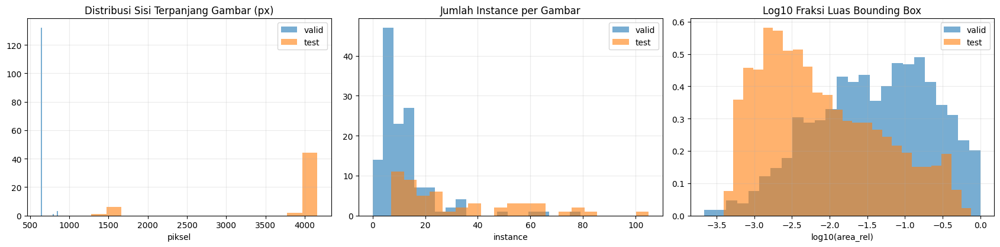

In [5]:
from collections import Counter
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Polygon

eda_rows, scale_rows = [], []
split_map = [(sp, json.loads((DATASET_ROOT / sp / "_annotations.coco.json").read_text(encoding="utf-8"))) for sp in AVAILABLE_SPLITS]

for sp, coco in split_map:
    img_wh = {int(im["id"]): (im["width"], im["height"]) for im in coco["images"]}
    ann_counts = Counter(int(a["image_id"]) for a in coco["annotations"] if int(a["category_id"]) != 0)
    for im in coco["images"]:
        eda_rows.append({
            "split": sp,
            "width": im["width"],
            "height": im["height"],
            "long_side": max(im["width"], im["height"]),
            "n_instances": ann_counts.get(int(im["id"]), 0),
        })
    for a in coco["annotations"]:
        if int(a["category_id"]) == 0:
            continue
        w, h = img_wh[int(a["image_id"])]
        area = float(a.get("area", 0))
        scale_bucket = "small (<32^2)" if area < 32 ** 2 else ("medium (<96^2)" if area < 96 ** 2 else "large (>=96^2)")
        scale_rows.append({
            "split": sp,
            "area_px": area,
            "bbox_frac": float(a["bbox"][2] * a["bbox"][3]) / max(w * h, 1),
            "scale_bucket": scale_bucket,
        })

eda_df = pd.DataFrame(eda_rows)
scale_df = pd.DataFrame(scale_rows)
print("Ringkasan dimensi citra & kepadatan instance per gambar:")
display(eda_df.groupby("split")[["long_side", "n_instances"]].agg(["count", "mean", "median", "min", "max"]).round(1))
print("Distribusi skala luas masker COCO (persentase per split):")
display(pd.crosstab(scale_df["split"], scale_df["scale_bucket"], normalize="index").mul(100).round(2))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.3))
for sp in AVAILABLE_SPLITS:
    sub = eda_df[eda_df["split"] == sp]
    axes[0].hist(sub["long_side"], bins=15, alpha=0.6, label=sp)
    axes[1].hist(sub["n_instances"], bins=20, alpha=0.6, label=sp)
    sub_s = scale_df[scale_df["split"] == sp]
    axes[2].hist(np.log10(np.clip(sub_s["bbox_frac"], 1e-6, 1.0)), bins=25, alpha=0.6, density=True, label=sp)

axes[0].set_title("Distribusi Sisi Terpanjang Gambar (px)"); axes[0].set_xlabel("piksel"); axes[0].legend(); axes[0].grid(alpha=.25)
axes[1].set_title("Jumlah Instance per Gambar"); axes[1].set_xlabel("instance"); axes[1].legend(); axes[1].grid(alpha=.25)
axes[2].set_title("Log10 Fraksi Luas Bounding Box"); axes[2].set_xlabel("log10(area_rel)"); axes[2].legend(); axes[2].grid(alpha=.25)
plt.tight_layout(); plt.savefig(OUT / "eda_test_vs_valid.png", dpi=140); plt.show()


### 4.2 Distribusi Kelas *Split* `test` dan Pratinjau *Ground Truth*

Kelas aktif pada split test: 46 | Total anotasi test: 1715


,class,test_instances,valid_instances
0,chair,305,59
1,wall-other-merged,214,253
2,person,181,69
3,table-merged,117,102
4,light,108,23
5,toy,107,77
6,window-other,83,44
7,floor-other-merged,69,67
8,tv,65,1
9,ceiling-merged,59,25


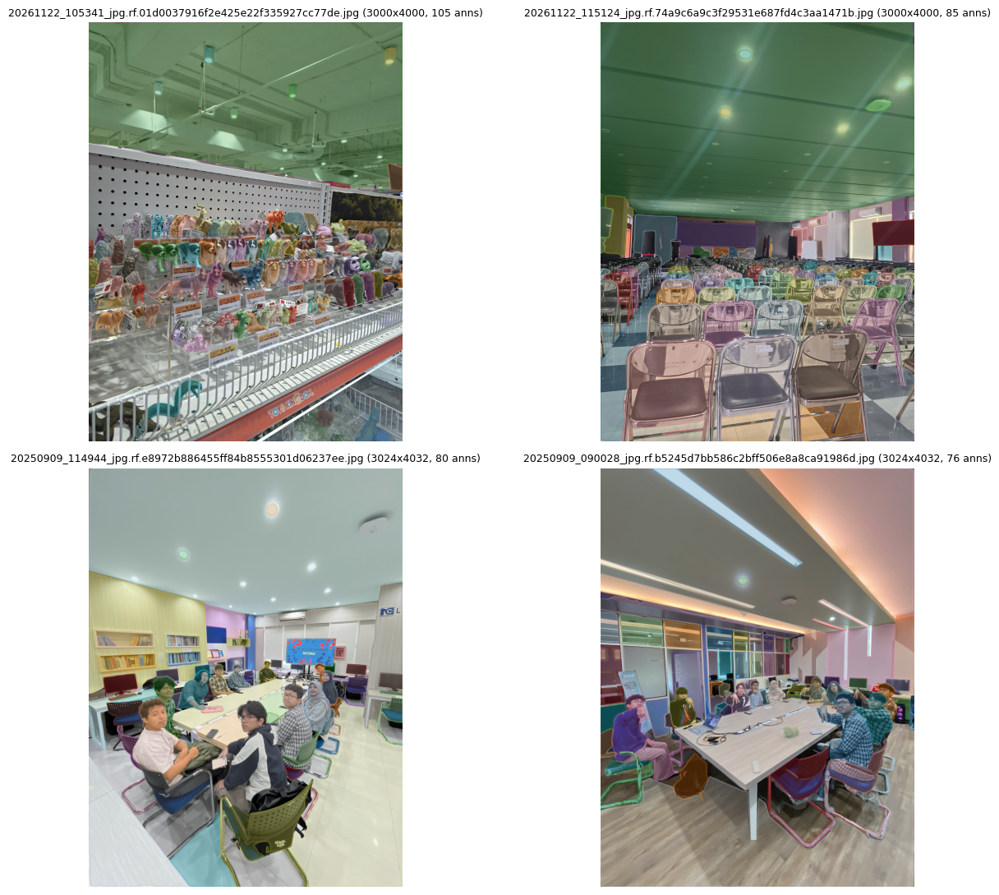

In [6]:
test_cat_names = {int(c["id"]): c["name"] for c in TEST_COCO["categories"]}
test_cls_counts = Counter(test_cat_names[int(a["category_id"])] for a in TEST_COCO["annotations"] if int(a["category_id"]) != 0)
cls_df = pd.DataFrame(test_cls_counts.most_common(), columns=["class", "test_instances"])
if VALID_COCO is not None:
    valid_cat_names = {int(c["id"]): c["name"] for c in VALID_COCO["categories"]}
    valid_cls_counts = Counter(valid_cat_names[int(a["category_id"])] for a in VALID_COCO["annotations"] if int(a["category_id"]) != 0)
    cls_df["valid_instances"] = cls_df["class"].map(lambda k: valid_cls_counts.get(k, 0))
print(f"Kelas aktif pada split test: {len(cls_df)} | Total anotasi test: {int(cls_df['test_instances'].sum())}")
display(cls_df.head(20))

# Pratinjau 4 sampel gambar test beserta poligon ground truth
sample_imgs = sorted(
    TEST_COCO["images"],
    key=lambda im: sum(1 for a in TEST_COCO["annotations"] if int(a["image_id"]) == int(im["id"])),
    reverse=True,
)[:4]
fig, axes = plt.subplots(2, 2, figsize=(15, 11))
for ax, im in zip(axes.flat, sample_imgs):
    with Image.open(DATASET_ROOT / "test" / im["file_name"]) as f:
        rgb = np.asarray(ImageOps.exif_transpose(f).convert("RGB"))
    ax.imshow(rgb)
    anns = [a for a in TEST_COCO["annotations"] if int(a["image_id"]) == int(im["id"]) and int(a["category_id"]) != 0]
    for j, a in enumerate(anns):
        col = plt.cm.tab20(j % 20)
        for poly in a["segmentation"]:
            pts = np.asarray(poly, dtype=float).reshape(-1, 2)
            if len(pts) >= 3:
                ax.add_patch(Polygon(pts, closed=True, facecolor=col, edgecolor=col, alpha=0.28, lw=1.2))
    ax.set_title(f"{im['file_name']} ({im['width']}x{im['height']}, {len(anns)} anns)", fontsize=9)
    ax.axis("off")
plt.tight_layout(); plt.savefig(OUT / "eda_test_samples.png", dpi=130); plt.show()


## 5. Fungsi *Inference* dan Evaluator COCO (`segm`)

Implementasi predictor untuk `YOLO26s-seg`, `Mask R-CNN v2`, dan `RF-DETR-Seg Small` beserta fungsi `coco_mask_eval` menyalin tepat konfigurasi evaluasi notebook training (`max_det = 100`, `conf = 0.001`) agar perbandingan skor `valid` dan `test` konsisten.

In [7]:
import contextlib, io
from pycocotools import mask as mu
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

METRICS = ("mask_mAP", "AP50", "AP75", "AP_small", "AP_medium", "AP_large", "AR100")


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def load_rgb(path):
    with Image.open(path) as im:
        return np.asarray(ImageOps.exif_transpose(im).convert("RGB"))


def decode(seg, h, w):
    if isinstance(seg, list):
        return mu.decode(mu.merge(mu.frPyObjects(seg, h, w))).astype(np.uint8)
    rle = dict(seg)
    if isinstance(rle.get("counts"), str):
        rle["counts"] = rle["counts"].encode("ascii")
    return mu.decode(rle).astype(np.uint8)


def remap_gt(src_json, dst_json, n2i):
    d = read_json(src_json)
    old = {int(c["id"]): c["name"] for c in d["categories"]}
    names = {c["name"] for c in d["categories"]}
    d["annotations"] = [
        dict(a, category_id=n2i[old[int(a["category_id"])]], iscrowd=int(a.get("iscrowd", 0)))
        for a in d["annotations"] if old.get(int(a["category_id"])) in n2i
    ]
    d["categories"] = [{"id": i, "name": n, "supercategory": "indoor"} for n, i in n2i.items()]
    Path(dst_json).write_text(json.dumps(d), encoding="utf-8")
    return sorted(n for n in names if n and n not in n2i)


def to_record(image_id, cat_id, score, mask):
    rle = mu.encode(np.asfortranarray(mask.astype(np.uint8)))
    rle["counts"] = rle["counts"].decode("ascii")
    return {"image_id": int(image_id), "category_id": int(cat_id), "segmentation": rle, "score": float(score)}


def predict_set(run, gt_json, image_root, max_det=100):
    recs = []
    for im in read_json(gt_json)["images"]:
        rgb = load_rgb(Path(image_root) / im["file_name"])
        if rgb.shape[:2] != (im["height"], im["width"]):
            raise ValueError(f"Ukuran {im['file_name']} {rgb.shape[:2]} != anotasi {(im['height'], im['width'])}")
        for c, s, m in sorted(run(rgb), key=lambda t: -t[1])[:max_det]:
            if m.any():
                recs.append(to_record(im["id"], c, s, m))
    return recs


def coco_mask_eval(gt_json, records, img_ids=None):
    with contextlib.redirect_stdout(io.StringIO()):
        gt = COCO(str(gt_json))
        if not records:
            return dict.fromkeys(METRICS, 0.0)
        ev = COCOeval(gt, gt.loadRes(records), "segm")
        if img_ids is not None:
            ev.params.imgIds = list(img_ids)
        ev.evaluate(); ev.accumulate(); ev.summarize()
    return dict(zip(METRICS, [float(ev.stats[i]) for i in (0, 1, 2, 3, 4, 5, 8)]))


def build_maskrcnn(num_classes, size):
    from torchvision.models.detection import maskrcnn_resnet50_fpn_v2
    from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
    from torchvision.models.detection.mask_rcnn import MaskRCNNPredictor

    m = maskrcnn_resnet50_fpn_v2(weights=None, weights_backbone=None, box_score_thresh=0.001, box_detections_per_img=MAX_DET)
    m.roi_heads.box_predictor = FastRCNNPredictor(m.roi_heads.box_predictor.cls_score.in_features, num_classes + 1)
    m.roi_heads.mask_predictor = MaskRCNNPredictor(m.roi_heads.mask_predictor.conv5_mask.in_channels, 256, num_classes + 1)
    m.transform.min_size, m.transform.max_size = (size,), size
    return m


def maskrcnn_runner(model, ids):
    device = next(model.parameters()).device

    def run(rgb):
        x = torch.from_numpy(rgb.copy()).permute(2, 0, 1).float().div(255).to(device)
        with torch.inference_mode(), torch.autocast(device.type, dtype=torch.float16, enabled=device.type == "cuda"):
            o = model([x])[0]
        masks = (o["masks"][:, 0].float() > 0.5).cpu().numpy()
        return [(ids[int(l) - 1], float(s), m) for l, s, m in zip(o["labels"].tolist(), o["scores"].tolist(), masks)]

    return run


def make_predictor(kind, weights, size, n2i):
    if kind == "yolo26s-seg":
        from ultralytics import YOLO
        model = YOLO(str(weights))
        names = model.names
        use_half = DEVICE == "cuda"
        dev = 0 if DEVICE == "cuda" else "cpu"

        def run(rgb):
            r = model.predict(
                rgb[..., ::-1].copy(), imgsz=size, conf=0.001, iou=0.7, max_det=MAX_DET,
                retina_masks=True, half=use_half, verbose=False, device=dev,
            )[0]
            if r.masks is None:
                return []
            masks = r.masks.data.cpu().numpy() > 0.5
            return [(n2i[names[int(c)]], s, m) for c, s, m in zip(r.boxes.cls.tolist(), r.boxes.conf.tolist(), masks)
                    if names[int(c)] in n2i]

        return run
    if kind == "maskrcnn-v2":
        model = build_maskrcnn(len(n2i), size)
        model.load_state_dict(torch.load(weights, map_location="cpu", weights_only=False)["model"])
        return maskrcnn_runner(model.to(DEVICE).eval(), sorted(n2i.values()))
    if kind == "rfdetr-seg-small":
        from rfdetr import RFDETRSegSmall
        model = RFDETRSegSmall(pretrain_weights=str(weights), resolution=size, trust_checkpoint=True)
        names = model.class_names

        def name_of(cid):
            cid = int(cid)
            if isinstance(names, dict):
                return names.get(cid)
            return names[cid] if 0 <= cid < len(names) else None

        def run(rgb):
            d = model.predict(Image.fromarray(rgb), threshold=0.001)
            if d.mask is None or len(d) == 0:
                return []
            out = []
            for c, s, m in zip(d.class_id, d.confidence, d.mask):
                nm = name_of(c)
                if nm in n2i:
                    out.append((n2i[nm], float(s), np.asarray(m, dtype=bool)))
            return out

        return run
    raise ValueError(kind)


## 6. Eksekusi *Inference* dan Evaluasi pada *Split* `test` dan `valid`

Prediksi tiap model disimpan dalam format COCO RLE di folder `EVAL_OUT`. Jika file cache `pred_<model>_<size>_<split>.json` sudah tersedia, evaluasi langsung memakainya tanpa mengulang inferensi GPU.

In [8]:
import gc

EVAL_SPLITS = ["test"] + (["valid"] if RUN_VALID_SPLIT and "valid" in AVAILABLE_SPLITS else [])
SETS = {sp: DATASET_ROOT / sp for sp in EVAL_SPLITS}
GT = {}
for sp, folder in SETS.items():
    GT[sp] = EVAL_OUT / f"gt_{sp}.json"
    ignored = remap_gt(folder / "_annotations.coco.json", GT[sp], NAME_TO_ID)
    print(f"Split {sp}: kelas diabaikan = {ignored}")

rows = []
for model in MODELS:
    for size in SIZES:
        weights = CHECKPOINTS[(model, size)]
        t_size = RFDETR_RES[size] if model.startswith("rfdetr") else size
        run = None
        for sp, folder in SETS.items():
            pred_file = EVAL_OUT / f"pred_{model}_{size}_{sp}.json"
            n_img = len(read_json(GT[sp])["images"])
            if pred_file.is_file() and pred_file.stat().st_size > 2:
                recs = read_json(pred_file)
                sec_per_img = float("nan")
            else:
                if run is None:
                    run = make_predictor(model, str(weights), t_size, NAME_TO_ID)
                t0 = time.time()
                recs = predict_set(run, GT[sp], folder, max_det=MAX_DET)
                sec_per_img = (time.time() - t0) / max(n_img, 1)
                pred_file.write_text(json.dumps(recs), encoding="utf-8")
            m = coco_mask_eval(GT[sp], recs)
            rows.append({
                "model": model, "size": size, "train_size": t_size, "set": sp,
                **m, "n_preds": len(recs), "sec_per_img": sec_per_img,
                "fps": (1.0 / sec_per_img) if sec_per_img == sec_per_img and sec_per_img > 0 else float("nan"),
            })
            print(f"{model:17s} | size={size:3d} | {sp:5s} | mAP={m['mask_mAP']:.4f} | AP50={m['AP50']:.4f} | AP75={m['AP75']:.4f} | AP_s={m['AP_small']:.4f} | {sec_per_img:.3f} s/img", flush=True)
        if run is not None:
            del run
            gc.collect()
            if torch.cuda.is_available():
                torch.cuda.empty_cache()

RESULTS = pd.DataFrame(rows)
RESULTS.to_csv(OUT / "test_eval_results.csv", index=False)

test_res = RESULTS[RESULTS["set"] == "test"]
print("\nTabel mask_mAP pada split test:")
display(test_res.pivot_table(index="model", columns="size", values="mask_mAP").round(4))

if "valid" in EVAL_SPLITS:
    piv_t = RESULTS[RESULTS["set"] == "test"].pivot(index="model", columns="size", values="mask_mAP")
    piv_v = RESULTS[RESULTS["set"] == "valid"].pivot(index="model", columns="size", values="mask_mAP")
    print("\nDomain shift mask_mAP (test - valid):")
    display((piv_t - piv_v).round(4))


Split test: kelas diabaikan = ['indoor-objects']
Split valid: kelas diabaikan = ['indoor-objects']


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


WARNING ⚠️ 'half' is deprecated and will be removed in the future. Use 'quantize' instead.


... (586 outputs left out)


Tabel mask_mAP pada split test:


size,320,640,960
model,,,
maskrcnn-v2,0.1092,0.1527,0.1773
rfdetr-seg-small,0.1737,0.2571,0.3005
yolo26s-seg,0.0983,0.1186,0.1489



Domain shift mask_mAP (test - valid):


size,320,640,960
model,,,
maskrcnn-v2,-0.0933,-0.0624,-0.0239
rfdetr-seg-small,-0.1356,-0.1341,-0.0867
yolo26s-seg,-0.1185,-0.0908,-0.1029


## 7. Visualisasi Performa, Uji H3, dan *Trade-off* Kecepatan

### 7.1 Tren *Mask* mAP, *Domain Shift*, dan `AP_small`

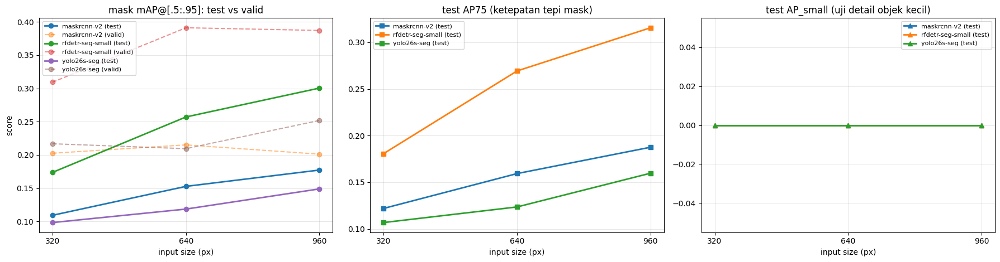

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
test_df = RESULTS[RESULTS["set"] == "test"]

for model, g in test_df.groupby("model"):
    g = g.sort_values("size")
    axes[0].plot(g["size"], g["mask_mAP"], marker="o", lw=2, label=f"{model} (test)")
    axes[1].plot(g["size"], g["AP75"], marker="s", lw=2, label=f"{model} (test)")
    axes[2].plot(g["size"], g["AP_small"], marker="^", lw=2, label=f"{model} (test)")
    if "valid" in EVAL_SPLITS:
        gv = RESULTS[(RESULTS["set"] == "valid") & (RESULTS["model"] == model)].sort_values("size")
        axes[0].plot(gv["size"], gv["mask_mAP"], marker="o", ls="--", alpha=0.5, label=f"{model} (valid)")

axes[0].set_title("mask mAP@[.5:.95]: test vs valid")
axes[1].set_title("test AP75 (ketepatan tepi mask)")
axes[2].set_title("test AP_small (uji detail objek kecil)")
for ax in axes:
    ax.set_xlabel("input size (px)"); ax.set_xticks(SIZES); ax.grid(alpha=0.3); ax.legend(fontsize=8)
axes[0].set_ylabel("score")
plt.tight_layout(); plt.savefig(OUT / "test_map_vs_size.png", dpi=150); plt.show()


### 7.2 *Trade-off* Akurasi vs Waktu *Inference* (`test`)

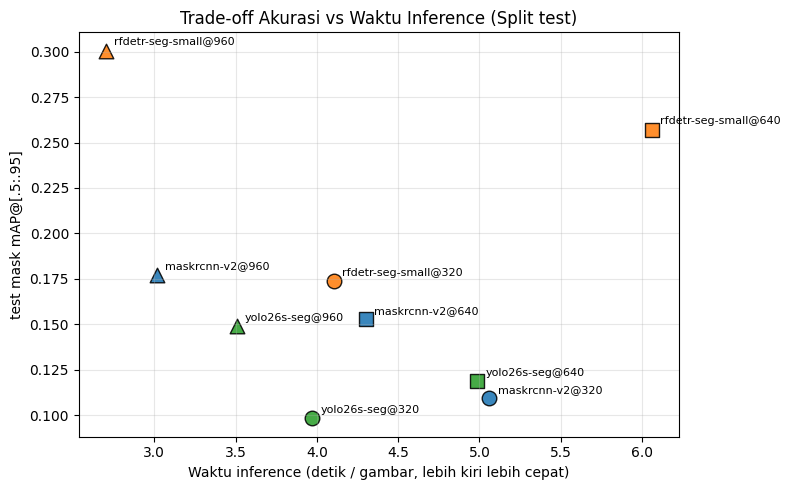

In [10]:
fig, ax = plt.subplots(figsize=(8, 5))
markers = {320: "o", 640: "s", 960: "^"}
colors = {"yolo26s-seg": "#2ca02c", "maskrcnn-v2": "#1f77b4", "rfdetr-seg-small": "#ff7f0e"}

for _, r in test_df.dropna(subset=["sec_per_img"]).iterrows():
    ax.scatter(r["sec_per_img"], r["mask_mAP"], s=110, marker=markers[int(r["size"])], color=colors[r["model"]], edgecolor="black", alpha=0.88)
    ax.annotate(f"{r['model']}@{int(r['size'])}", (r["sec_per_img"], r["mask_mAP"]), xytext=(6, 4), textcoords="offset points", fontsize=8)

ax.set_title("Trade-off Akurasi vs Waktu Inference (Split test)")
ax.set_xlabel("Waktu inference (detik / gambar, lebih kiri lebih cepat)")
ax.set_ylabel("test mask mAP@[.5:.95]")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(OUT / "test_tradeoff_speed_accuracy.png", dpi=150); plt.show()


### 7.3 Ringkasan Uji Hipotesis (H3 dan *Domain Shift*)

In [11]:
from IPython.display import Markdown

lines = []
for model, g in RESULTS.groupby("model"):
    gt_m = g[g["set"] == "test"].set_index("size")["mask_mAP"]
    gt_s = g[g["set"] == "test"].set_index("size")["AP_small"]
    best_t = gt_m.idxmax()
    d_test = gt_m.get(960, np.nan) - gt_m.get(640, np.nan)
    ds_test = gt_s.get(960, np.nan) - gt_s.get(640, np.nan)
    msg = (
        f"- **{model}** pada `test`: mAP tertinggi di **{best_t} px (`{gt_m[best_t]:.4f}`)**; "
        f"selisih `960 - 640` = **`{d_test:+.4f}`** (`AP_small`: `{ds_test:+.4f}`)."
    )
    if "valid" in EVAL_SPLITS:
        gv_m = g[g["set"] == "valid"].set_index("size")["mask_mAP"]
        d_val = gv_m.get(960, np.nan) - gv_m.get(640, np.nan)
        shift = gt_m.get(best_t, np.nan) - gv_m.get(best_t, np.nan)
        msg += f" Selisih `960 - 640` di `valid` = `{d_val:+.4f}`; *domain shift* di {best_t} px = **`{shift:+.4f}`**."
    lines.append(msg)

best_row = test_df.sort_values("mask_mAP", ascending=False).iloc[0]
lines.append(f"\n**Konfigurasi terbaik di `test`:** `{best_row['model']}@{int(best_row['size'])}` dengan `mask_mAP = {best_row['mask_mAP']:.4f}`, `AP50 = {best_row['AP50']:.4f}`, `AP75 = {best_row['AP75']:.4f}`.")
display(Markdown("\n".join(lines)))


- **maskrcnn-v2** pada `test`: mAP tertinggi di **960 px (`0.1773`)**; selisih `960 - 640` = **`+0.0245`** (`AP_small`: `+0.0000`). Selisih `960 - 640` di `valid` = `-0.0139`; *domain shift* di 960 px = **`-0.0239`**.
- **rfdetr-seg-small** pada `test`: mAP tertinggi di **960 px (`0.3005`)**; selisih `960 - 640` = **`+0.0434`** (`AP_small`: `+0.0000`). Selisih `960 - 640` di `valid` = `-0.0040`; *domain shift* di 960 px = **`-0.0867`**.
- **yolo26s-seg** pada `test`: mAP tertinggi di **960 px (`0.1489`)**; selisih `960 - 640` = **`+0.0303`** (`AP_small`: `+0.0000`). Selisih `960 - 640` di `valid` = `+0.0424`; *domain shift* di 960 px = **`-0.1029`**.

**Konfigurasi terbaik di `test`:** `rfdetr-seg-small@960` dengan `mask_mAP = 0.3005`, `AP50 = 0.3874`, `AP75 = 0.3155`.

## 8. Galeri Visual *Inference* (`test`): *Ground Truth* vs Prediksi Tiga Arsitektur

Sel berikut menampilkan perbandingan berdampingan antara *ground truth* dan prediksi ketiga model pada resolusi `COMPARE_SIZE = 640` dengan ambang konfidensi `VIS_CONF = 0.35`.

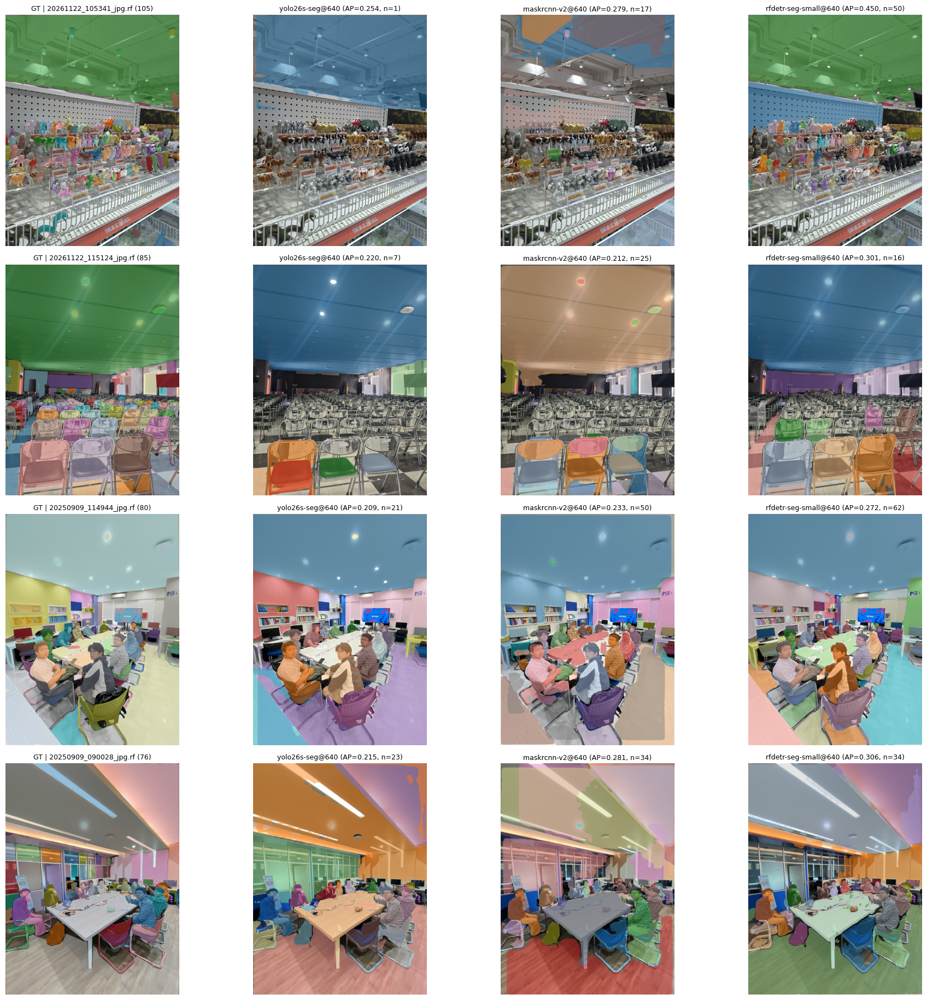

In [12]:
COMPARE_SIZE = 640
gt_test = read_json(GT["test"])
id_to_cls = {int(c["id"]): c["name"] for c in gt_test["categories"]}

sample_vis = sorted(
    gt_test["images"],
    key=lambda im: sum(1 for a in gt_test["annotations"] if int(a["image_id"]) == int(im["id"])),
    reverse=True,
)[:4]

preds_cache = {
    m: read_json(EVAL_OUT / f"pred_{m}_{COMPARE_SIZE}_test.json")
    for m in MODELS if (EVAL_OUT / f"pred_{m}_{COMPARE_SIZE}_test.json").is_file()
}


def draw_masks(rgb, masks, labels=None):
    over = rgb.copy()
    for k, m in enumerate(masks):
        sel = m.astype(bool)
        if not sel.any():
            continue
        col = np.array(plt.cm.tab20(k % 20)[:3]) * 255
        over[sel] = (0.52 * over[sel] + 0.48 * col).astype(np.uint8)
    return over


n_cols = 1 + len(preds_cache)
fig, axes = plt.subplots(len(sample_vis), n_cols, figsize=(4.8 * n_cols, 4.6 * len(sample_vis)), squeeze=False)
for r_idx, im in enumerate(sample_vis):
    rgb = load_rgb(SETS["test"] / im["file_name"])
    gt_masks = [decode(a["segmentation"], im["height"], im["width"]) for a in gt_test["annotations"] if int(a["image_id"]) == int(im["id"])]
    axes[r_idx, 0].imshow(draw_masks(rgb, gt_masks))
    axes[r_idx, 0].set_title(f"GT | {Path(im['file_name']).name[:22]} ({len(gt_masks)})", fontsize=9)
    axes[r_idx, 0].axis("off")

    for c_idx, model in enumerate(MODELS, 1):
        if model not in preds_cache:
            continue
        recs = [r for r in preds_cache[model] if int(r["image_id"]) == int(im["id"]) and r["score"] >= VIS_CONF]
        pmasks = [decode(r["segmentation"], im["height"], im["width"]) for r in recs]
        ap_img = coco_mask_eval(GT["test"], [r for r in preds_cache[model] if int(r["image_id"]) == int(im["id"])], [im["id"]])["mask_mAP"]
        axes[r_idx, c_idx].imshow(draw_masks(rgb, pmasks))
        axes[r_idx, c_idx].set_title(f"{model}@{COMPARE_SIZE} (AP={ap_img:.3f}, n={len(pmasks)})", fontsize=9)
        axes[r_idx, c_idx].axis("off")

plt.tight_layout(); plt.savefig(OUT / f"test_visual_comparison_{COMPARE_SIZE}.png", dpi=130); plt.show()


## 9. Analisis Kegagalan pada *Split* `test`

Lima gambar `test` dengan nilai AP terendah per model pada ukuran `640` piksel ditampilkan berdampingan dengan *ground truth*, kemudian dibandingkan kembali skornya di `320`, `640`, dan `960` piksel untuk membedakan masalah resolusi dari masalah kelas atau oklusi.

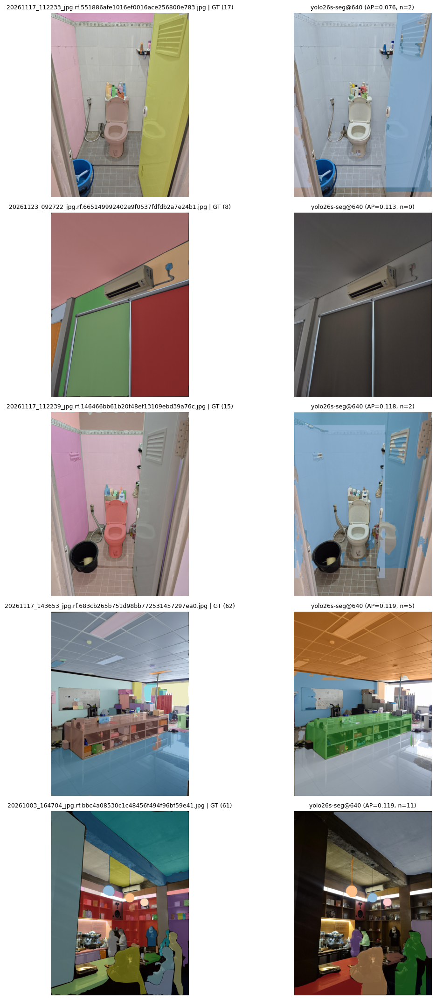

,model,file,AP@320,AP@640,AP@960
0,yolo26s-seg,20261117_112233_jpg.rf.551886afe1016ef0016ace2...,0.087,0.076,0.343
1,yolo26s-seg,20261123_092722_jpg.rf.665149992402e9f0537fdfd...,0.000,0.112,0.083
2,yolo26s-seg,20261117_112239_jpg.rf.146466bb61b20f48ef13109...,0.202,0.118,0.126
3,yolo26s-seg,20261117_143653_jpg.rf.683cb265b751d98bb772531...,0.156,0.119,0.242
4,yolo26s-seg,20261003_164704_jpg.rf.bbc4a08530c1c48456f494f...,0.036,0.119,0.096


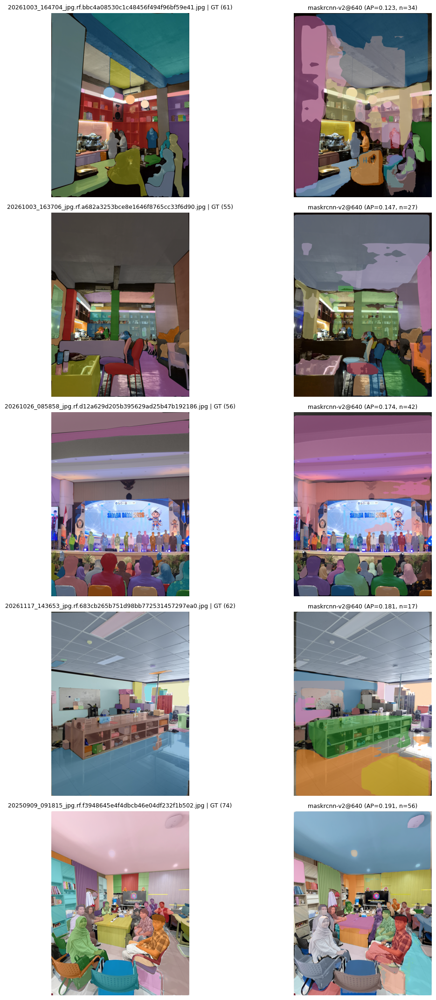

,model,file,AP@320,AP@640,AP@960
0,maskrcnn-v2,20261003_164704_jpg.rf.bbc4a08530c1c48456f494f...,0.095,0.123,0.217
1,maskrcnn-v2,20261003_163706_jpg.rf.a682a3253bce8e1646f8765...,0.106,0.147,0.212
2,maskrcnn-v2,20261026_085858_jpg.rf.d12a629d205b395629ad25b...,0.128,0.174,0.200
3,maskrcnn-v2,20261117_143653_jpg.rf.683cb265b751d98bb772531...,0.165,0.181,0.199
4,maskrcnn-v2,20250909_091815_jpg.rf.f3948645e4f4dbcb46e04df...,0.141,0.191,0.213


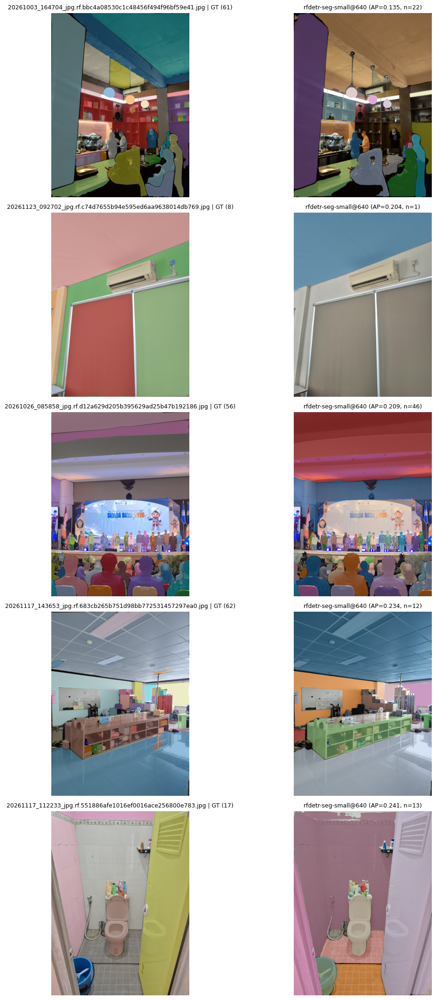

,model,file,AP@320,AP@640,AP@960
0,rfdetr-seg-small,20261003_164704_jpg.rf.bbc4a08530c1c48456f494f...,0.108,0.135,0.207
1,rfdetr-seg-small,20261123_092702_jpg.rf.c74d7655b94e595ed6aa963...,0.263,0.204,0.203
2,rfdetr-seg-small,20261026_085858_jpg.rf.d12a629d205b395629ad25b...,0.153,0.209,0.219
3,rfdetr-seg-small,20261117_143653_jpg.rf.683cb265b751d98bb772531...,0.166,0.234,0.371
4,rfdetr-seg-small,20261117_112233_jpg.rf.551886afe1016ef0016ace2...,0.183,0.241,0.387


In [13]:
FAIL_SIZE = 640
gt = read_json(GT["test"])

for FAIL_MODEL in MODELS:
    pred_path = EVAL_OUT / f"pred_{FAIL_MODEL}_{FAIL_SIZE}_test.json"
    if not pred_path.exists():
        continue
    recs = read_json(pred_path)
    per_img = [
        (im, coco_mask_eval(GT["test"], [r for r in recs if int(r["image_id"]) == int(im["id"])], [im["id"]])["mask_mAP"])
        for im in gt["images"]
    ]
    worst = sorted(per_img, key=lambda t: t[1])[:5]
    fig, axes = plt.subplots(len(worst), 2, figsize=(13, 4.3 * len(worst)), squeeze=False)
    for (im, ap), (a0, a1) in zip(worst, axes):
        rgb = load_rgb(SETS["test"] / im["file_name"])
        gt_masks = [decode(a["segmentation"], im["height"], im["width"]) for a in gt["annotations"] if int(a["image_id"]) == int(im["id"])]
        pr_masks = [decode(r["segmentation"], im["height"], im["width"]) for r in recs if int(r["image_id"]) == int(im["id"]) and r["score"] >= VIS_CONF]
        a0.imshow(draw_masks(rgb, gt_masks)); a0.set_title(f"{im['file_name']} | GT ({len(gt_masks)})", fontsize=9); a0.axis("off")
        a1.imshow(draw_masks(rgb, pr_masks)); a1.set_title(f"{FAIL_MODEL}@{FAIL_SIZE} (AP={ap:.3f}, n={len(pr_masks)})", fontsize=9); a1.axis("off")
    plt.tight_layout(); plt.savefig(OUT / f"test_failures_{FAIL_MODEL}_{FAIL_SIZE}.png", dpi=110); plt.show()

    preds_by_size = {
        s: read_json(p) for s in SIZES if (p := EVAL_OUT / f"pred_{FAIL_MODEL}_{s}_test.json").exists()
    }
    rows_fail = []
    for im, _ in worst:
        row = {"model": FAIL_MODEL, "file": im["file_name"]}
        for s, rs in preds_by_size.items():
            row[f"AP@{s}"] = coco_mask_eval(GT["test"], [r for r in rs if int(r["image_id"]) == int(im["id"])], [im["id"]])["mask_mAP"]
        rows_fail.append(row)
    display(pd.DataFrame(rows_fail).round(3))


### 9.1 Rincian Performa per Kelas pada `test` (Model Terbaik)

In [14]:
best_m = test_df.sort_values("mask_mAP", ascending=False).iloc[0]
b_model, b_size = best_m["model"], int(best_m["size"])
b_recs = read_json(EVAL_OUT / f"pred_{b_model}_{b_size}_test.json")

with contextlib.redirect_stdout(io.StringIO()):
    gt_coco = COCO(str(GT["test"]))
    dt_coco = gt_coco.loadRes(b_recs) if b_recs else None

cat_rows = []
for c in gt_coco.dataset["categories"]:
    cid, cname = int(c["id"]), c["name"]
    n_gt = sum(1 for a in gt_coco.dataset["annotations"] if int(a["category_id"]) == cid)
    if n_gt == 0 or dt_coco is None:
        continue
    with contextlib.redirect_stdout(io.StringIO()):
        ev = COCOeval(gt_coco, dt_coco, "segm")
        ev.params.catIds = [cid]
        ev.evaluate(); ev.accumulate(); ev.summarize()
    cat_rows.append({"class": cname, "n_gt_test": n_gt, "mask_mAP": float(ev.stats[0]), "AP50": float(ev.stats[1])})

cls_eval_df = pd.DataFrame(cat_rows).sort_values("mask_mAP", ascending=False)
print(f"15 kelas terbaik di test ({b_model}@{b_size}):")
display(cls_eval_df.head(15).round(4))
print(f"15 kelas terendah di test ({b_model}@{b_size}):")
display(cls_eval_df.tail(15).round(4))
cls_eval_df.to_csv(OUT / f"per_class_test_{b_model}_{b_size}.csv", index=False)


15 kelas terbaik di test (rfdetr-seg-small@960):


,class,n_gt_test,mask_mAP,AP50
36,toilet,3,1.0000,1.0000
39,trash-bin,1,1.0000,1.0000
5,bowl,1,0.9000,1.0000
34,sink,1,0.8000,1.0000
23,laptop,19,0.6464,0.7030
28,person,181,0.6314,0.8544
11,clock,5,0.5941,0.7360
14,cup,12,0.5787,0.7275
8,ceiling-merged,59,0.5581,0.6993
18,floor-other-merged,69,0.5578,0.6705


15 kelas terendah di test (rfdetr-seg-small@960):


,class,n_gt_test,mask_mAP,AP50
29,pillow,7,0.1020,0.1499
31,potted plant,3,0.1010,0.3366
30,plug,15,0.0789,0.1428
3,book,42,0.0715,0.1470
21,handbag,6,0.0568,0.1143
12,couch,2,0.0316,0.0316
44,window-blind,9,0.0248,0.0682
42,wall-tile,5,0.0242,0.1107
2,blanket,1,0.0186,0.0233
43,wall-wood,27,0.0075,0.0163


## 10. Pengemasan Output Evaluasi

Seluruh CSV ringkasan, grafik perbandingan, analisis kegagalan, dan cache RLE dikemas ke `instance_seg_inference_outputs.zip` agar praktis diunduh.

In [15]:
BUNDLE = LOCAL_WORK / "instance_seg_inference_bundle"
if BUNDLE.exists():
    shutil.rmtree(BUNDLE)
BUNDLE.mkdir(parents=True)

for pat in ("*.csv", "*.png"):
    for p in OUT.glob(pat):
        shutil.copy2(p, BUNDLE / p.name)
if EVAL_OUT.exists():
    shutil.copytree(EVAL_OUT, BUNDLE / "eval", dirs_exist_ok=True)

zip_out = shutil.make_archive(str(OUT / "instance_seg_inference_outputs"), "zip", root_dir=BUNDLE)
print("Arsip evaluasi siap:", zip_out, f"({Path(zip_out).stat().st_size / 1e6:.1f} MB)")


Arsip evaluasi siap: /content/drive/MyDrive/instance_seg_inference_results/instance_seg_inference_outputs.zip (100.8 MB)


## 11. Keterbatasan dan Kesimpulan Akhir

### Keterbatasan
- Evaluasi `test` memakai *checkpoint* tunggal hasil training `seed = 42` sehingga belum mengukur simpangan antar-*seed*.
- Foto *test* berasal dari ruangan nyata dengan kepadatan tinggi dan beberapa benda yang tidak termasuk dalam `74` kelas latih (misalnya unit pendingin ruangan dinding), yang dapat menekan skor mAP absolut secara seragam.
- Inferensi `RF-DETR-Seg Small` menggunakan kelipatan `24` terdekat (`312`, `648`, `960`) selaras dengan konfigurasi saat training.

### Kesimpulan Evaluasi (`test` Set Mandiri S24 FE vs `valid`, NVIDIA L4)
1. **Model terbaik:** `RF-DETR-Seg Small@960` menempati peringkat pertama pada *split* `test` dengan `mask mAP = 0.3005`, `AP50 = 0.3874`, `AP75 = 0.3155`, dan `AR100 = 0.4343`, unggul jauh atas `Mask R-CNN v2@960` (`0.1773`) dan `YOLO26s-seg@960` (`0.1489`).
2. **Pembuktian Hipotesis H3 (`640 -> 960` piksel):** Pada foto `test` yang beresolusi tinggi (rata-rata `3677.0 px`, median `4000.0 px`), memperbesar ukuran input dari `640` ke `960` piksel menaikkan `mask mAP` ketiga model secara serempak: `RF-DETR` naik `+0.0434` (`0.2571 -> 0.3005`), `YOLO26s-seg` naik `+0.0303` (`0.1186 -> 0.1489`), dan `Mask R-CNN v2` naik `+0.0246` (`0.1527 -> 0.1773`). `AP_medium` `RF-DETR` ikut melonjak hampir dua kali lipat (`0.1003 -> 0.1873`), sedangkan `AP_small` bernilai `0.0` di `test` karena hampir seluruh anotasi berluas `>= 32^2 px` (`99.94%`).
3. ***Domain shift* (`test - valid`):** Ketiga arsitektur mengalami penurunan skor saat dihadapkan pada foto ruangan lokal dengan kepadatan tiga kali lebih tinggi (`32.4` vs `11.9` *instance* per gambar) dan pencahayaan menantang. Di `960` piksel, `Mask R-CNN v2` mencatat selisih *domain shift* terkecil (`-0.0239`), sementara `RF-DETR-Seg Small` (`-0.0867`) dan `YOLO26s-seg` (`-0.1029`).
4. **Performa kelas:** Kelas umum berstruktur tegas seperti `laptop` (`0.6464`), `person` (`0.6314`), `cup` (`0.5787`), `ceiling-merged` (`0.5581`), `floor-other-merged` (`0.5578`), dan `tv` (`0.5099`) tersegmentasi dengan baik, sedangkan kelas bertekstur tipis atau berekor panjang (`wall-wood` `0.0075`, `paper-merged` `0.0050`, `book` `0.0715`, `plug` `0.0789`) menjadi titik lemah utama.